# Notebook 3: Evaluation, Thresholds, Baselines and Statistical Tests

Runs on the laptop (no training here, only scoring and analysis, a few minutes in total).
It reads the saved anomaly scores from `../Results/runs_final/` and produces every results table and
figure for Chapter 5.

| Research question | What this notebook does | Output |
|---|---|---|
| RQ1: AE vs VAE under identical conditions | Test-set Precision, Recall, F1, AUC-ROC, AUC-PR (mean and std over 5 seeds), paired t-test across seeds and a bootstrap confidence interval for the AUC difference | Tables 5.x, ROC and PR curves |
| RQ2: fixed vs calibrated threshold | Fixed thresholds (95th and 99th percentile of normal scores, no labels) against the calibrated threshold (F1-maximising point on the labelled validation period) | Threshold table, paired t-test |
| RQ3: consistency across the two fraud types | The same tables side by side for IEEE-CIS and BAF (multi-dataset replication) | Comparison table |
| RQ4: error distributions of normal vs fraud | KDE plots of test reconstruction error and two-sample Kolmogorov-Smirnov (KS) tests | KDE figure, KS table |

Two extra pieces give context:
* **Baselines:** PCA reconstruction error and Isolation Forest, trained on the same training normals.
* **Ablation:** the standard VAE (beta = 1) from the first round, which suffered posterior collapse.

The test labels are used only to compute the final metrics, never to choose a threshold or a model.

**At a glance**

| | |
|---|---|
| Run on | Laptop (no training, only scoring and statistics) |
| Run time | A few minutes (Isolation Forest is the slowest part) |
| Reads | `../Processed/*.npz`, `../Results/runs_final/`, `../Results/runs_beta1/`, `best_latent.json` |
| Writes | All results tables in `../Results/tables/`; ROC/PR, confusion matrix and KDE figures in `../Figures/` |
| Run order | Step 4 of 6, after Notebooks 02 and 02b. |

In [2]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, roc_curve, confusion_matrix)
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
warnings.filterwarnings("ignore", category=UserWarning)

BASE = os.path.abspath("..")
PROC = os.path.join(BASE, "Processed")
RUNS = os.path.join(BASE, "Results", "runs_final")
RUNS_B1 = os.path.join(BASE, "Results", "runs_beta1")
TAB_DIR = os.path.join(BASE, "Results", "tables")
FIG_DIR = os.path.join(BASE, "Figures")
os.makedirs(TAB_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 12, "axes.titlesize": 13,
                     "axes.labelsize": 12, "font.family": "Times New Roman"})
sns.set_style("whitegrid")
NAMES = {"ieee": "IEEE-CIS", "baf": "BAF"}
COL = {"AE": "#4C72B0", "VAE": "#DD8452", "PCA": "#55A868", "IForest": "#8172B3"}
SEEDS = [0, 1, 2, 3, 4]
with open(os.path.join(BASE, "Results", "best_latent.json")) as f:
    BEST = json.load(f)
BETA = 0.01
print("Chosen latent sizes:", BEST)

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight"); print("saved", name)

def savetab(df, name):
    df.to_csv(os.path.join(TAB_DIR, name)); print("saved", name)

def load_labels(ds):
    d = np.load(os.path.join(PROC, f"{ds}.npz"))
    return d["y_val"], d["y_test"]

def run_dir(ds, model, seed, root=RUNS, beta=BETA):
    z = BEST[f"{ds}_{model}"]
    return os.path.join(root, f"{ds}_AE_z{z}_s{seed}" if model == "AE" else f"{ds}_VAE_b{beta:g}_z{z}_s{seed}")

def load_scores(path):
    return {k: np.load(os.path.join(path, f"scores_{k}.npy")) for k in ("es", "val", "test")}

Chosen latent sizes: {'baf_AE': 32, 'baf_VAE': 8, 'ieee_AE': 32, 'ieee_VAE': 16}


## Threshold rules and metrics

* **Fixed (unsupervised):** the 95th or 99th percentile of the anomaly scores of the early-stop normals.
  No labels at all. A 95th percentile threshold flags roughly 5% of normal traffic by design.
* **Calibrated (label-assisted):** the threshold that maximises F1 on the validation period, read from its
  precision-recall curve. This needs validation labels, which is stated openly in the thesis.
  The chosen threshold is then applied unchanged to the later test period.

In [4]:
def thr_fixed(s, q):
    return float(np.quantile(s["es"], q))

def thr_calibrated(s, y_val):
    p, r, t = precision_recall_curve(y_val, s["val"])
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.argmax(f1[:-1])])

def metrics(y, score, thr):
    pred = (score >= thr).astype(int)
    return {"precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
            "f1": f1_score(y, pred), "flagged_%": 100 * pred.mean(),
            "auc_roc": roc_auc_score(y, score), "auc_pr": average_precision_score(y, score)}

def evaluate(ds, model, s, y_val, y_test, seed):
    rows = []
    for rule, thr in [("fixed_p95", thr_fixed(s, 0.95)), ("fixed_p99", thr_fixed(s, 0.99)),
                      ("calibrated_F1", thr_calibrated(s, y_val))]:
        rows.append({"dataset": NAMES[ds], "model": model, "seed": seed, "threshold_rule": rule,
                     "threshold": thr, **metrics(y_test, s["test"], thr)})
    return rows

## Baselines: PCA and Isolation Forest

Both are fitted on the same training normals. PCA uses the same number of components as the AE latent size,
and its score is the mean squared reconstruction error, so it is the linear version of the AE.
Isolation Forest is a standard tree-based anomaly detector (200 trees, 5 seeds).
They are reference points only and are not part of the AE vs VAE comparison.

In [6]:
def baseline_scores(ds):
    d = np.load(os.path.join(PROC, f"{ds}.npz"))
    out = {}
    pca = PCA(n_components=BEST[f"{ds}_AE"], random_state=0).fit(d["X_train"])
    rec = lambda X: ((X - pca.inverse_transform(pca.transform(X))) ** 2).mean(axis=1)
    out[("PCA", 0)] = {k: rec(d[f"X_{k}"]) for k in ("es", "val", "test")}
    for seed in SEEDS:
        iso = IsolationForest(n_estimators=200, random_state=seed, n_jobs=-1).fit(d["X_train"])
        out[("IForest", seed)] = {k: -iso.score_samples(d[f"X_{k}"]) for k in ("es", "val", "test")}
    return out

rows, SCORES = [], {}
for ds in ["ieee", "baf"]:
    y_val, y_test = load_labels(ds)
    for model in ["AE", "VAE"]:
        for seed in SEEDS:
            s = load_scores(run_dir(ds, model, seed))
            SCORES[(ds, model, seed)] = s
            rows += evaluate(ds, model, s, y_val, y_test, seed)
    for (model, seed), s in baseline_scores(ds).items():
        SCORES[(ds, model, seed)] = s
        rows += evaluate(ds, model, s, y_val, y_test, seed)
    print(NAMES[ds], "done")
res = pd.DataFrame(rows)
savetab(res, "all_runs_test_metrics.csv")

IEEE-CIS done
BAF done
saved all_runs_test_metrics.csv


## RQ1: AE vs VAE on the test period

Mean and standard deviation over the 5 seeds, using the calibrated threshold.
AUC-ROC and AUC-PR do not depend on the threshold. For reference, a random detector scores
AUC-ROC 0.5 and AUC-PR equal to the fraud rate (3.48% on IEEE-CIS, 1.47% on BAF).

In [8]:
def mean_std(df, cols):
    g = df.groupby(["dataset", "model"], sort=False)[cols]
    m, s = g.mean(), g.std().fillna(0)
    return pd.DataFrame({c: [f"{a:.4f} ± {b:.4f}" for a, b in zip(m[c], s[c])] for c in cols}, index=m.index)

cols = ["precision", "recall", "f1", "auc_roc", "auc_pr"]
order = {"AE": 0, "VAE": 1, "PCA": 2, "IForest": 3}
cal = res[res.threshold_rule == "calibrated_F1"].copy()
cal["o"] = cal.model.map(order); cal = cal.sort_values(["dataset", "o"], ascending=[False, True])
table_main = mean_std(cal, cols)
savetab(table_main, "table_main_results_calibrated.csv")
table_main

saved table_main_results_calibrated.csv


precision           recall               f1  \
dataset  model                                                        
IEEE-CIS AE       0.1360 ± 0.0041  0.2779 ± 0.0128  0.1825 ± 0.0024   
         VAE      0.1353 ± 0.0058  0.2431 ± 0.0269  0.1732 ± 0.0045   
         PCA      0.1534 ± 0.0000  0.2254 ± 0.0000  0.1825 ± 0.0000   
         IForest  0.1822 ± 0.0027  0.3674 ± 0.0140  0.2435 ± 0.0027   
BAF      AE       0.0177 ± 0.0024  0.5700 ± 0.3929  0.0326 ± 0.0021   
         VAE      0.0174 ± 0.0021  0.6279 ± 0.4235  0.0328 ± 0.0030   
         PCA      0.0230 ± 0.0000  0.1366 ± 0.0000  0.0394 ± 0.0000   
         IForest  0.0235 ± 0.0036  0.1063 ± 0.0309  0.0377 ± 0.0032   

                          auc_roc           auc_pr  
dataset  model                                      
IEEE-CIS AE       0.7119 ± 0.0049  0.0886 ± 0.0013  
         VAE      0.7031 ± 0.0035  0.0846 ± 0.0012  
         PCA      0.7321 ± 0.0000  0.0949 ± 0.0000  
         IForest  0.7712 ± 0.0021  0.1179 ± 0.0017  
BAF      AE       0.5414 ± 0.0242  0.0167 ± 0.0011  
         VAE      0.5534 ± 0.0356  0.0173 ± 0.0016  
         PCA      0.5401 ± 0.0000  0.0180 ± 0.0000  
         IForest  0.5921 ± 0.0255  0.0199 ± 0.0018

### Is the AE vs VAE difference significant?

Two checks:
1. **Paired t-test across seeds** (seed i of the AE paired with seed i of the VAE). With 5 pairs this test has
   low power, so a non-significant result does not prove the models are equal.
2. **Bootstrap 95% confidence interval** of the AUC difference on the test set (1,000 resamples of the test
   transactions, averaged over the 5 seed pairs). If the interval does not include 0, the difference is unlikely
   to be due to chance in the test sample.

In [10]:
def paired_tests(metric, rule="calibrated_F1"):
    out = []
    for ds in ["IEEE-CIS", "BAF"]:
        a = res[(res.dataset == ds) & (res.model == "AE") & (res.threshold_rule == rule)].sort_values("seed")[metric].values
        v = res[(res.dataset == ds) & (res.model == "VAE") & (res.threshold_rule == rule)].sort_values("seed")[metric].values
        t, p = stats.ttest_rel(a, v)
        d = (a - v).mean() / (a - v).std(ddof=1) if (a - v).std(ddof=1) > 0 else np.nan
        out.append({"dataset": ds, "metric": metric, "AE_mean": a.mean(), "VAE_mean": v.mean(),
                    "difference_AE_minus_VAE": a.mean() - v.mean(), "t": t, "p_value": p, "cohens_d": d})
    return out

def bootstrap_diff(ds, metric_fn, n_boot=1000, seed=0):
    _, y = load_labels(ds)
    rng = np.random.RandomState(seed)
    diffs = []
    for _ in range(n_boot):
        idx = rng.randint(0, len(y), len(y))
        if y[idx].sum() == 0:
            continue
        diffs.append(np.mean([metric_fn(y[idx], SCORES[(ds, "AE", s)]["test"][idx]) -
                              metric_fn(y[idx], SCORES[(ds, "VAE", s)]["test"][idx]) for s in SEEDS]))
    return np.percentile(diffs, [2.5, 97.5])

sig = pd.DataFrame(sum([paired_tests(m) for m in ["auc_roc", "auc_pr", "f1"]], []))
ci = {}
for ds in ["ieee", "baf"]:
    for name, fn in [("auc_roc", roc_auc_score), ("auc_pr", average_precision_score)]:
        ci[(NAMES[ds], name)] = bootstrap_diff(ds, fn, n_boot=1000)
sig["bootstrap_95CI"] = [f"[{ci[(r.dataset, r.metric)][0]:.4f}, {ci[(r.dataset, r.metric)][1]:.4f}]"
                         if (r.dataset, r.metric) in ci else "" for r in sig.itertuples()]
sig = sig.round(4)
savetab(sig, "table_ae_vs_vae_significance.csv")
sig

saved table_ae_vs_vae_significance.csv


,dataset,metric,AE_mean,VAE_mean,difference_AE_minus_VAE,t,p_value,cohens_d,bootstrap_95CI
0,IEEE-CIS,auc_roc,0.7119,0.7031,0.0088,2.5234,0.0651,1.1285,"[0.0063, 0.0112]"
1,BAF,auc_roc,0.5414,0.5534,-0.0120,-0.8382,0.4491,-0.3749,"[-0.0160, -0.0082]"
2,IEEE-CIS,auc_pr,0.0886,0.0846,0.0041,3.7167,0.0205,1.6622,"[0.0034, 0.0048]"
3,BAF,auc_pr,0.0167,0.0173,-0.0005,-0.6211,0.5681,-0.2778,"[-0.0010, 0.0001]"
4,IEEE-CIS,f1,0.1825,0.1732,0.0093,3.5375,0.0241,1.5820,
5,BAF,f1,0.0326,0.0328,-0.0002,-0.1899,0.8587,-0.0849,


saved roc_pr_curves.png


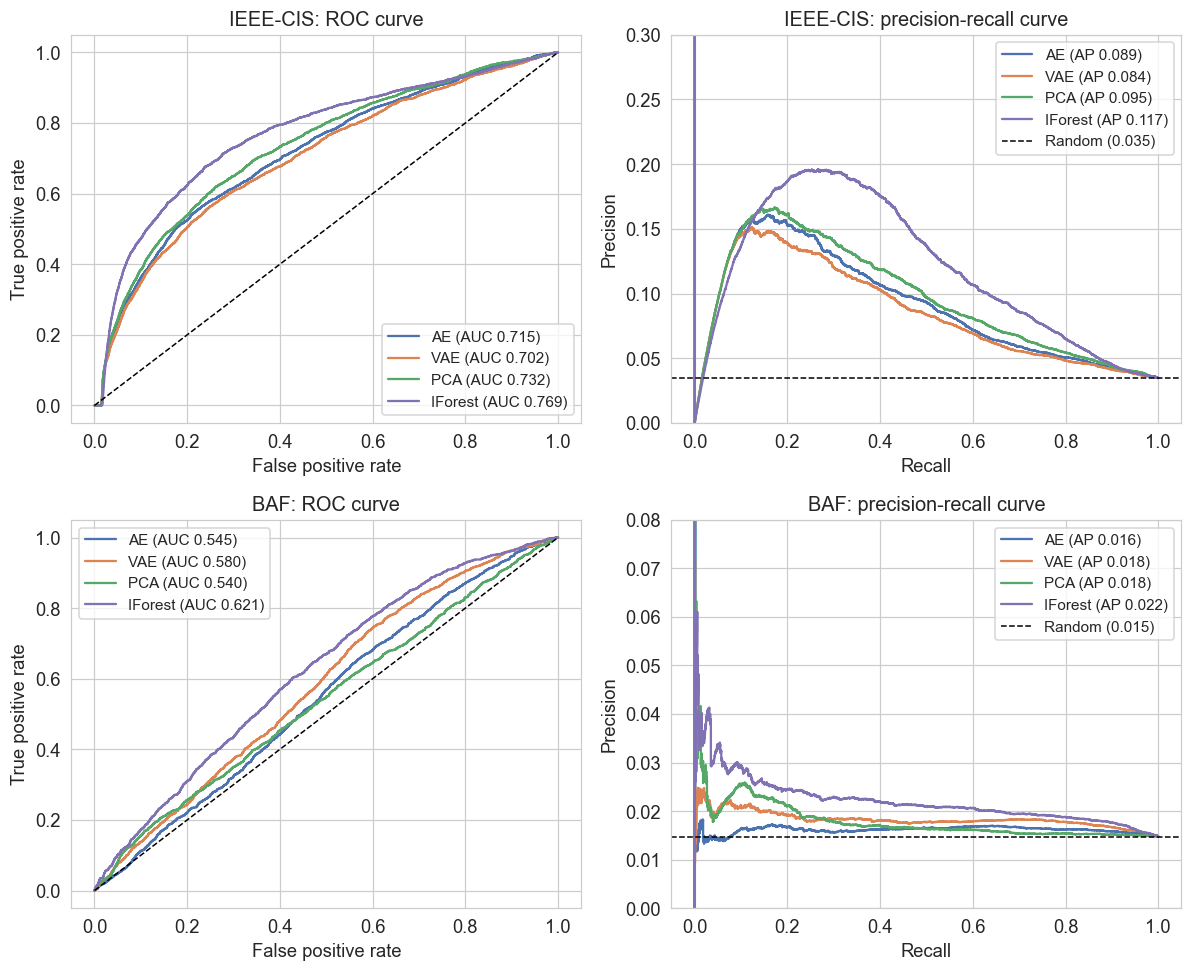

In [11]:
# ROC and precision-recall curves on the test period (seed 0 for AE, VAE and Isolation Forest)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, ds in enumerate(["ieee", "baf"]):
    _, y = load_labels(ds)
    for m in ["AE", "VAE", "PCA", "IForest"]:
        sc = SCORES[(ds, m, 0)]["test"]
        fpr, tpr, _ = roc_curve(y, sc)
        axes[row, 0].plot(fpr, tpr, color=COL[m], label=f"{m} (AUC {roc_auc_score(y, sc):.3f})")
        p, r, _ = precision_recall_curve(y, sc)
        axes[row, 1].plot(r, p, color=COL[m], label=f"{m} (AP {average_precision_score(y, sc):.3f})")
    axes[row, 0].plot([0, 1], [0, 1], "k--", lw=1)
    axes[row, 1].axhline(y.mean(), color="k", ls="--", lw=1, label=f"Random ({y.mean():.3f})")
    axes[row, 0].set(title=f"{NAMES[ds]}: ROC curve", xlabel="False positive rate", ylabel="True positive rate")
    axes[row, 1].set(title=f"{NAMES[ds]}: precision-recall curve", xlabel="Recall", ylabel="Precision")
    axes[row, 1].set_ylim(0, 0.3 if ds == "ieee" else 0.08)   # zoom in, the curves sit close to the bottom
    for ax in axes[row]:
        ax.legend(fontsize=10)
plt.tight_layout(); savefig("roc_pr_curves.png"); plt.show()

## RQ2: fixed vs calibrated threshold

F1 on the test period under each threshold rule. The paired t-test compares the calibrated threshold with
the fixed 95th percentile threshold for each model, across the 5 seeds.

In [13]:
thr_tab = (res[res.model.isin(["AE", "VAE"])]
           .groupby(["dataset", "model", "threshold_rule"], sort=False)[["precision", "recall", "f1", "flagged_%"]]
           .agg(["mean", "std"]).round(4))
savetab(thr_tab, "table_threshold_comparison.csv")
display(thr_tab)

rq2 = []
for ds in ["IEEE-CIS", "BAF"]:
    for m in ["AE", "VAE"]:
        sub = res[(res.dataset == ds) & (res.model == m)]
        cal_f1 = sub[sub.threshold_rule == "calibrated_F1"].sort_values("seed").f1.values
        for rule in ["fixed_p95", "fixed_p99"]:
            fx = sub[sub.threshold_rule == rule].sort_values("seed").f1.values
            t, p = stats.ttest_rel(cal_f1, fx)
            rq2.append({"dataset": ds, "model": m, "compared_with": rule, "F1_calibrated": cal_f1.mean(),
                        "F1_fixed": fx.mean(), "gain": cal_f1.mean() - fx.mean(), "t": t, "p_value": p})
rq2 = pd.DataFrame(rq2).round(4)
savetab(rq2, "table_rq2_threshold_tests.csv")
rq2

saved table_threshold_comparison.csv


precision          recall              f1  \
                                   mean     std    mean     std    mean   
dataset  model threshold_rule                                             
IEEE-CIS AE    fixed_p95         0.1333  0.0015  0.2830  0.0048  0.1813   
               fixed_p99         0.1580  0.0024  0.1443  0.0049  0.1508   
               calibrated_F1     0.1360  0.0041  0.2779  0.0128  0.1825   
         VAE   fixed_p95         0.1274  0.0018  0.2785  0.0053  0.1748   
               fixed_p99         0.1502  0.0033  0.1388  0.0049  0.1443   
               calibrated_F1     0.1353  0.0058  0.2431  0.0269  0.1732   
BAF      AE    fixed_p95         0.0181  0.0037  0.0737  0.0081  0.0290   
               fixed_p99         0.0201  0.0051  0.0153  0.0033  0.0173   
               calibrated_F1     0.0177  0.0024  0.5700  0.3929  0.0326   
         VAE   fixed_p95         0.0192  0.0041  0.0749  0.0137  0.0305   
               fixed_p99         0.0218  0.0054  0.0158  0.0032  0.0183   
               calibrated_F1     0.0174  0.0021  0.6279  0.4235  0.0328   

                                      flagged_%           
                                  std      mean      std  
dataset  model threshold_rule                             
IEEE-CIS AE    fixed_p95       0.0023    7.3889   0.0602  
               fixed_p99       0.0031    3.1799   0.1063  
               calibrated_F1   0.0024    7.1239   0.5250  
         VAE   fixed_p95       0.0013    7.6077   0.2339  
               fixed_p99       0.0041    3.2160   0.0475  
               calibrated_F1   0.0045    6.2797   0.9422  
BAF      AE    fixed_p95       0.0053    6.1101   0.7202  
               fixed_p99       0.0040    1.1330   0.1188  
               calibrated_F1   0.0021   51.0986  37.9781  
         VAE   fixed_p95       0.0061    5.8080   0.6245  
               fixed_p99       0.0040    1.0836   0.1058  
               calibrated_F1   0.0030   56.8659  41.9015

saved table_rq2_threshold_tests.csv


,dataset,model,compared_with,F1_calibrated,F1_fixed,gain,t,p_value
0,IEEE-CIS,AE,fixed_p95,0.1825,0.1813,0.0012,1.4899,0.2105
1,IEEE-CIS,AE,fixed_p99,0.1825,0.1508,0.0316,14.0203,0.0002
2,IEEE-CIS,VAE,fixed_p95,0.1732,0.1748,-0.0016,-0.8106,0.4631
3,IEEE-CIS,VAE,fixed_p99,0.1732,0.1443,0.0289,15.6848,0.0001
4,BAF,AE,fixed_p95,0.0326,0.0290,0.0036,2.1599,0.0969
5,BAF,AE,fixed_p99,0.0326,0.0173,0.0153,14.2211,0.0001
6,BAF,VAE,fixed_p95,0.0328,0.0305,0.0023,0.8802,0.4285
7,BAF,VAE,fixed_p99,0.0328,0.0183,0.0145,7.0684,0.0021


saved confusion_matrices.png


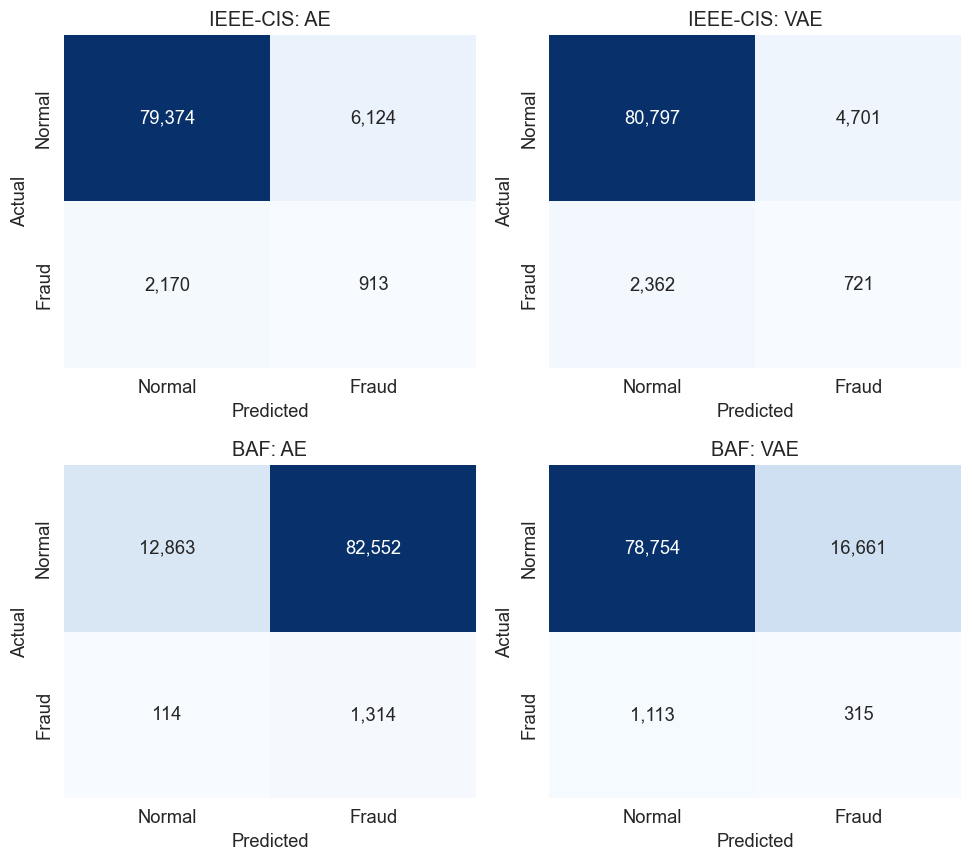

In [14]:
# Confusion matrices at the calibrated threshold (seed 0)
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for row, ds in enumerate(["ieee", "baf"]):
    y_val, y = load_labels(ds)
    for col, m in enumerate(["AE", "VAE"]):
        s = SCORES[(ds, m, 0)]
        cm = confusion_matrix(y, (s["test"] >= thr_calibrated(s, y_val)).astype(int))
        sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[row, col],
                    xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"])
        axes[row, col].set(title=f"{NAMES[ds]}: {m}", xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); savefig("confusion_matrices.png"); plt.show()

## RQ3: consistency across the two fraud types

The same results side by side. Consistent findings would mean the same model wins on both datasets
by a similar margin. Note: this is multi-dataset replication (each model is trained and tested within one dataset),
not cross-dataset validation, because the two datasets have different features.

In [16]:
rq3 = (cal[cal.model.isin(["AE", "VAE"])].groupby(["model", "dataset"])[["auc_roc", "auc_pr", "f1"]].mean()
       .unstack("dataset").round(4))
lift = cal[cal.model.isin(["AE", "VAE"])].copy()
# divide by the test-period fraud rate (the AUC-PR of a random detector): 3.48% and 1.47%
lift["auc_pr_lift_over_random"] = lift.apply(lambda r: r.auc_pr / {"IEEE-CIS": 0.0348, "BAF": 0.0147}[r.dataset], axis=1)
rq3_lift = lift.groupby(["model", "dataset"]).auc_pr_lift_over_random.mean().unstack().round(2)
savetab(rq3, "table_rq3_consistency.csv"); savetab(rq3_lift, "table_rq3_aucpr_lift.csv")
display(rq3); rq3_lift

saved table_rq3_consistency.csv
saved table_rq3_aucpr_lift.csv


auc_roc           auc_pr               f1         
dataset     BAF IEEE-CIS     BAF IEEE-CIS     BAF IEEE-CIS
model                                                     
AE       0.5414   0.7119  0.0167   0.0886  0.0326   0.1825
VAE      0.5534   0.7031  0.0173   0.0846  0.0328   0.1732

dataset,BAF,IEEE-CIS
model,,
AE,1.14,2.55
VAE,1.17,2.43


## RQ4: reconstruction error distributions

KDE plots of the test reconstruction error (log scale) for normal and fraudulent transactions,
and the two-sample KS statistic D (0 = identical distributions, 1 = completely separated).

saved error_distributions_kde.png


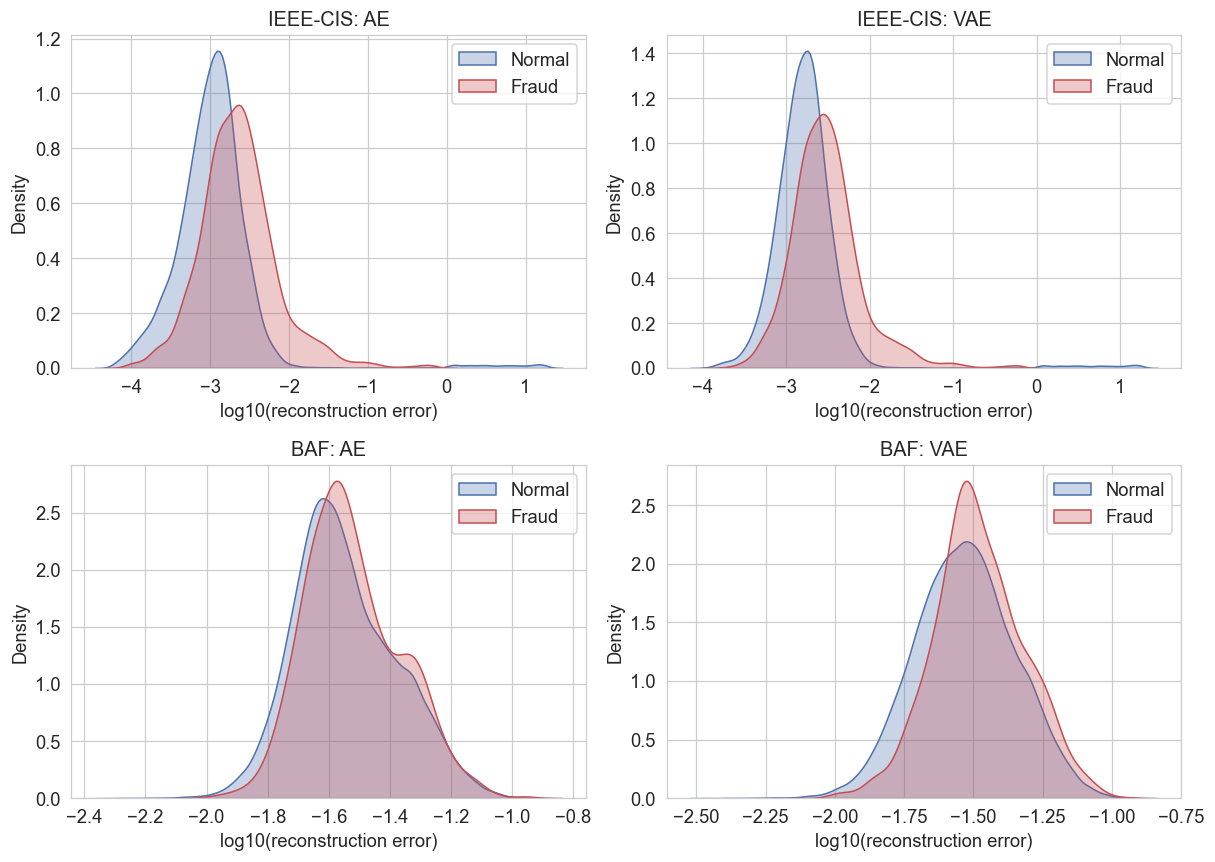

saved table_rq4_ks_tests.csv


KS_D_mean  KS_D_std  max_p_value  median_normal  median_fraud  \
dataset  model                                                                  
IEEE-CIS AE       0.32381   0.01159      0.00000        0.00103       0.00207   
         VAE      0.31027   0.00658      0.00000        0.00155       0.00272   
BAF      AE       0.08248   0.04026      0.17272        0.02750       0.02877   
         VAE      0.10618   0.05534      0.00246        0.03174       0.03326   

                fraud_to_normal_ratio  
dataset  model                         
IEEE-CIS AE                   2.00877  
         VAE                  1.75357  
BAF      AE                   1.04641  
         VAE                  1.04812

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
ks_rows = []
for row, ds in enumerate(["ieee", "baf"]):
    _, y = load_labels(ds)
    for col, m in enumerate(["AE", "VAE"]):
        sc = SCORES[(ds, m, 0)]["test"]
        ax = axes[row, col]
        for lab, name, c in [(0, "Normal", "#4C72B0"), (1, "Fraud", "#C44E52")]:
            sns.kdeplot(np.log10(sc[y == lab] + 1e-8), ax=ax, label=name, color=c, fill=True, alpha=0.3,
                        common_norm=False)
        ax.set(title=f"{NAMES[ds]}: {m}", xlabel="log10(reconstruction error)", ylabel="Density"); ax.legend()
    for m in ["AE", "VAE"]:
        for seed in SEEDS:
            sc = SCORES[(ds, m, seed)]["test"]
            D, p = stats.ks_2samp(sc[y == 1], sc[y == 0])
            ks_rows.append({"dataset": NAMES[ds], "model": m, "seed": seed, "KS_D": D, "p_value": p,
                            "median_error_normal": np.median(sc[y == 0]), "median_error_fraud": np.median(sc[y == 1])})
plt.tight_layout(); savefig("error_distributions_kde.png"); plt.show()

ks = pd.DataFrame(ks_rows)
ks_tab = ks.groupby(["dataset", "model"], sort=False).agg(KS_D_mean=("KS_D", "mean"), KS_D_std=("KS_D", "std"),
        max_p_value=("p_value", "max"), median_normal=("median_error_normal", "mean"),
        median_fraud=("median_error_fraud", "mean"))
ks_tab["fraud_to_normal_ratio"] = ks_tab.median_fraud / ks_tab.median_normal
ks_tab = ks_tab.round(5)
savetab(ks_tab, "table_rq4_ks_tests.csv")
ks_tab

## Ablation: the standard VAE (beta = 1)

The first round of runs used the standard KL weight. Active latent units show the posterior collapse,
and the test metrics show what it did to detection.

In [20]:
abl = []
for ds in ["ieee", "baf"]:
    y_val, y_test = load_labels(ds)
    names = [n for n in os.listdir(RUNS_B1) if n.startswith(f"{ds}_VAE_")]
    zs = sorted({int(n.split("_z")[1].split("_")[0]) for n in names})
    for z in zs:
        for seed in SEEDS:
            p = os.path.join(RUNS_B1, f"{ds}_VAE_z{z}_s{seed}")
            if not os.path.exists(os.path.join(p, "meta.json")):
                continue
            meta = json.load(open(os.path.join(p, "meta.json")))
            s = load_scores(p)
            m = metrics(y_test, s["test"], thr_calibrated(s, y_val))
            abl.append({"dataset": NAMES[ds], "variant": "VAE beta=1", "latent": z, "seed": seed,
                        "active_units": meta.get("active_latent_units"), **m})
    for seed in SEEDS:
        meta = json.load(open(os.path.join(run_dir(ds, "VAE", seed), "meta.json")))
        s = SCORES[(ds, "VAE", seed)]
        m = metrics(y_test, s["test"], thr_calibrated(s, y_val))
        abl.append({"dataset": NAMES[ds], "variant": f"VAE beta={BETA:g}", "latent": BEST[f"{ds}_VAE"], "seed": seed,
                    "active_units": meta.get("active_latent_units"), **m})
abl = pd.DataFrame(abl)
abl_tab = abl.groupby(["dataset", "variant", "latent"], sort=False)[["active_units", "auc_roc", "auc_pr", "f1"]].agg(["mean", "std"]).round(4)
savetab(abl_tab, "table_ablation_beta.csv")
abl_tab

saved table_ablation_beta.csv


active_units         auc_roc          auc_pr  \
                                      mean     std    mean     std    mean   
dataset  variant       latent                                                
IEEE-CIS VAE beta=1    8               1.0     NaN  0.6680     NaN  0.0655   
                       16              1.0     NaN  0.6655     NaN  0.0649   
                       32              1.0  0.0000  0.6724  0.0059  0.0671   
         VAE beta=0.01 16              5.6  0.5477  0.7031  0.0035  0.0846   
BAF      VAE beta=1    8               0.0     NaN  0.5804     NaN  0.0187   
                       16              0.0  0.0000  0.5824  0.0009  0.0188   
                       32              0.0     NaN  0.5806     NaN  0.0187   
         VAE beta=0.01 8               5.0  0.0000  0.5534  0.0356  0.0173   

                                           f1          
                                  std    mean     std  
dataset  variant       latent                          
IEEE-CIS VAE beta=1    8          NaN  0.1269     NaN  
                       16         NaN  0.1263     NaN  
                       32      0.0019  0.1293  0.0029  
         VAE beta=0.01 16      0.0012  0.1732  0.0045  
BAF      VAE beta=1    8          NaN  0.0350     NaN  
                       16      0.0001  0.0349  0.0002  
                       32         NaN  0.0349     NaN  
         VAE beta=0.01 8       0.0016  0.0328  0.0030

## Training summary for Chapter 4

Epochs, training time and parameter count of the final configurations (5 seeds each).

In [22]:
tr = []
for ds in ["ieee", "baf"]:
    for m in ["AE", "VAE"]:
        for seed in SEEDS:
            meta = json.load(open(os.path.join(run_dir(ds, m, seed), "meta.json")))
            tr.append({"dataset": NAMES[ds], "model": m, **{k: meta.get(k) for k in
                       ["latent", "n_params", "epochs_run", "best_epoch", "train_seconds", "device", "active_latent_units"]}})
tr = pd.DataFrame(tr)
tr_tab = tr.groupby(["dataset", "model", "latent", "n_params", "device"], sort=False)[["epochs_run", "best_epoch", "train_seconds", "active_latent_units"]].agg(["mean", "std"]).round(1)
savetab(tr_tab, "table_training_summary.csv")
tr_tab

saved table_training_summary.csv


epochs_run       best_epoch        \
                                            mean   std       mean   std   
dataset  model latent n_params device                                     
IEEE-CIS AE    32     301891   cuda        150.0   0.0      148.4   1.9   
         VAE   16     300867   cuda        137.4  22.0      135.6  21.0   
BAF      AE    32     18034    cuda        103.6  18.8      102.0  19.8   
         VAE   8      16738    cuda         92.6  22.5       90.8  23.3   

                                      train_seconds       active_latent_units  \
                                               mean   std                mean   
dataset  model latent n_params device                                           
IEEE-CIS AE    32     301891   cuda            88.2   0.4                 NaN   
         VAE   16     300867   cuda           104.7  16.9                 5.6   
BAF      AE    32     18034    cuda           117.9  21.3                 NaN   
         VAE   8      16738    cuda           136.7  33.4                 5.0   

                                            
                                       std  
dataset  model latent n_params device       
IEEE-CIS AE    32     301891   cuda    NaN  
         VAE   16     300867   cuda    0.5  
BAF      AE    32     18034    cuda    NaN  
         VAE   8      16738    cuda    0.0